# HCD Data Exploration and Parse Pseudobulk Audit

**Scope:** exploratory inspection only. This notebook does **not** generate final pseudobulk datasets or training/validation splits.

The workflow inventories the data, verifies normalization and aggregation levels from metadata and values, compares the supplied Parse profiles with the full HCD single-cell data, and records an evidence-based reusability decision.

## 0. Imports

In [13]:
import os
import json
import re
import warnings
import zipfile
import tarfile
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import sparse
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad
import scanpy as sc
from IPython.display import display

warnings.filterwarnings('ignore')
np.random.seed(42)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 150})
print('Imports ready')

Imports ready


## 1. Project configuration

Set `PROJECT_DIR` manually only if automatic detection fails. The notebook can be launched from the project root or `notebooks/`.

This repository contains a full HCD candidate and a 54k-cell subset. The full candidate is selected explicitly below; inspect the inventory before changing it. `FULL_DATA_PATH = None` remains available for a strict manual-selection workflow.

In [14]:
def detect_project_dir():
    candidates = [Path.cwd(), Path.cwd().parent]
    candidates += [p.resolve() for p in candidates]
    for candidate in candidates:
        if (candidate / 'data').exists() and (candidate / 'README.md').exists():
            return candidate
    raise FileNotFoundError('Could not find the cytoX project directory. Set PROJECT_DIR manually below.')

try:
    PROJECT_DIR = detect_project_dir()
except FileNotFoundError:
    PROJECT_DIR = Path('/Users/svneni/f26/idl/cyto-project/cytoX')  # Manual fallback

DATA_DIR = PROJECT_DIR / 'data'
FULL_DATA_DIR = DATA_DIR / '10M_PBMC_12donor_90cytokines'
PSEUDOBULK_DIR = DATA_DIR / 'pseudobulks'
NOTEBOOK_DIR = PROJECT_DIR / 'notebooks'
AUDIT_OUTPUT_DIR = PROJECT_DIR / 'data' / 'hcd_audit_summaries'
HCD_SUBSET_PATH = DATA_DIR / 'hcd_subset.h5ad'

# Explicit full-dataset selection. Override this path if a different HCD file is intended.
FULL_DATA_PATH = FULL_DATA_DIR / '10M_PBMC_cytokines.h5ad'
MIDTERM_REPORT_PATH = PROJECT_DIR / 'Group51_Midterm_Report (1).pdf'

for path in [DATA_DIR, FULL_DATA_DIR, PSEUDOBULK_DIR]:
    print(f'{path.name}: {path} ({"exists" if path.exists() else "MISSING"})')
print(f'PROJECT_DIR: {PROJECT_DIR}')
print(f'FULL_DATA_PATH: {FULL_DATA_PATH}')
print(f'MIDTERM_REPORT_PATH: {MIDTERM_REPORT_PATH}')
AUDIT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

data: /Users/svneni/f26/idl/cyto-project/cytoX/data (exists)
10M_PBMC_12donor_90cytokines: /Users/svneni/f26/idl/cyto-project/cytoX/data/10M_PBMC_12donor_90cytokines (exists)
pseudobulks: /Users/svneni/f26/idl/cyto-project/cytoX/data/pseudobulks (exists)
PROJECT_DIR: /Users/svneni/f26/idl/cyto-project/cytoX
FULL_DATA_PATH: /Users/svneni/f26/idl/cyto-project/cytoX/data/10M_PBMC_12donor_90cytokines/10M_PBMC_cytokines.h5ad
MIDTERM_REPORT_PATH: /Users/svneni/f26/idl/cyto-project/cytoX/Group51_Midterm_Report (1).pdf


## 2. Section A: Inventory all available files

In [15]:
def format_size(size_bytes):
    size_mb = size_bytes / (1024 ** 2)
    if size_mb >= 1024:
        return f'{size_mb / 1024:.2f} GB'
    return f'{size_mb:.2f} MB'

ARCHIVE_SUFFIXES = ('.zip', '.tar', '.tar.gz', '.tgz')

def classify_file(path):
    name = path.name.lower()
    if name.endswith('.h5ad'):
        kind = 'AnnData/HDF5'
    elif name.endswith(ARCHIVE_SUFFIXES):
        kind = 'archive'
    elif name.endswith('.h5'):
        kind = 'HDF5'
    elif name.endswith('.csv'):
        kind = 'CSV table'
    elif name.endswith('.tsv'):
        kind = 'TSV table'
    elif name.endswith('.pdf'):
        kind = 'PDF document'
    else:
        kind = 'other'
    compressed = name.endswith(('.gz', '.zip', '.bz2', '.xz', '.tgz'))
    return kind, compressed

def inspect_archive(path, max_entries=100):
    try:
        if path.name.lower().endswith('.zip'):
            with zipfile.ZipFile(path) as zf:
                return zf.namelist()[:max_entries]
        with tarfile.open(path, 'r:*') as tf:
            return tf.getnames()[:max_entries]
    except Exception as exc:
        return [f'Unreadable archive: {exc}']

def inventory_directory(root):
    rows = []
    archive_rows = []
    if not root.exists():
        return pd.DataFrame(rows), pd.DataFrame(archive_rows)
    for path in sorted(root.rglob('*')):
        if not path.is_file() or path.name == '.DS_Store':
            continue
        kind, compressed = classify_file(path)
        rows.append({
            'relative_filename': str(path.relative_to(root)),
            'extension': path.suffix.lower() or '(none)',
            'size': format_size(path.stat().st_size),
            'compressed': compressed,
            'type': kind,
        })
        if kind == 'archive':
            entries = inspect_archive(path)
            archive_rows.append({'archive': str(path.relative_to(root)),
                                 'sample_internal_entries': '\n'.join(entries)})
    return pd.DataFrame(rows), pd.DataFrame(archive_rows)

full_inventory, full_archives = inventory_directory(FULL_DATA_DIR)
parse_inventory, parse_archives = inventory_directory(PSEUDOBULK_DIR)
print('Full-data directory inventory')
display(full_inventory)
print('Parse pseudobulk inventory')
display(parse_inventory.head(30))
print(f'Parse inventory row count: {len(parse_inventory)}')
if not parse_archives.empty:
    display(parse_archives)

h5ad_candidates = list(DATA_DIR.rglob('*.h5ad'))
h5ad_candidates = [p for p in h5ad_candidates if 'pseudobulk_runs' not in p.parts and 'pseudobulks' not in p.parts]
print('Potential full-dataset H5AD candidates')
display(pd.DataFrame([{
    'path': str(p.relative_to(PROJECT_DIR)),
    'size': format_size(p.stat().st_size),
} for p in h5ad_candidates]))

if not FULL_DATA_PATH.exists():
    raise FileNotFoundError(f'FULL_DATA_PATH does not exist: {FULL_DATA_PATH}')

Full-data directory inventory


,relative_filename,extension,size,compressed,type
0,10M_PBMC_cytokines.h5ad,.h5ad,41.32 GB,False,AnnData/HDF5
1,LICENSE,(none),0.02 MB,False,other
2,README,(none),0.00 MB,False,other


Parse pseudobulk inventory


,relative_filename,extension,size,compressed,type
0,PBS_by_well/pbulk_B_cell_PBS_sum.h5ad,.h5ad,19.93 MB,False,AnnData/HDF5
1,PBS_by_well/pbulk_CD14_Mono_PBS_sum.h5ad,.h5ad,29.50 MB,False,AnnData/HDF5
2,PBS_by_well/pbulk_CD16_Mono_PBS_sum.h5ad,.h5ad,11.85 MB,False,AnnData/HDF5
3,PBS_by_well/pbulk_CD4_Memory_T_cell_PBS_sum.h5ad,.h5ad,27.56 MB,False,AnnData/HDF5
4,PBS_by_well/pbulk_CD4_Naive_T_cell_PBS_sum.h5ad,.h5ad,30.81 MB,False,AnnData/HDF5
5,PBS_by_well/pbulk_CD4_T_cell_PBS_sum.h5ad,.h5ad,46.81 MB,False,AnnData/HDF5
6,PBS_by_well/pbulk_CD8_Memory_T_cell_PBS_sum.h5ad,.h5ad,17.87 MB,False,AnnData/HDF5
7,PBS_by_well/pbulk_CD8_Naive_T_cell_PBS_sum.h5ad,.h5ad,17.66 MB,False,AnnData/HDF5
8,PBS_by_well/pbulk_CD8_T_cell_PBS_sum.h5ad,.h5ad,25.89 MB,False,AnnData/HDF5
9,PBS_by_well/pbulk_Granulocyte_PBS_sum.h5ad,.h5ad,3.08 MB,False,AnnData/HDF5


Parse inventory row count: 2088
Potential full-dataset H5AD candidates


,path,size
0,data/hcd_subset.h5ad,111.10 MB
1,data/10M_PBMC_12donor_90cytokines/10M_PBMC_cyt...,41.32 GB
2,data/pseudobulk_runs_full/sum_counts__min5__IL...,0.72 MB
3,data/pseudobulk_runs_full/sum_counts__min5__IL...,0.77 MB
4,data/pseudobulk_runs_full/pooled_donor__min10_...,0.49 MB
...,...,...
446,data/pseudobulk_runs_full/pseudobulk_data/mean...,5.19 MB
447,data/pseudobulk_runs_full/pseudobulk_data/sum_...,4.14 MB
448,data/pseudobulk_runs_full/pseudobulk_data/mean...,5.19 MB
449,data/pseudobulk_runs_full/pseudobulk_data/pool...,1.20 MB


### A interpretation

The inventory should distinguish source H5AD files from experiment outputs. In this repository, `hcd_subset.h5ad` is a processed subset and the 44 GB file is the full HCD candidate. The Parse directory contains one file per cell type/cytokine plus a separate well-level PBS collection.

## 3. Section B: Inspect the full HCD single-cell dataset

In [16]:
# Backed mode avoids loading the full 44 GB expression matrix into memory.
adata = ad.read_h5ad(FULL_DATA_PATH, backed='r')
print(f'Loaded in backed mode: {adata.shape[0]:,} cells x {adata.shape[1]:,} genes')

Loaded in backed mode: 9,697,974 cells x 40,352 genes


### B1. Basic dataset structure

In [17]:
print('AnnData dimensions:', adata.shape)
print('X sparse:', sparse.issparse(adata.X) or hasattr(adata.X, 'format'))
print('X dtype:', getattr(adata.X, 'dtype', 'unknown'))
print('X dataset type:', type(adata.X).__name__)
print('obs columns:', list(adata.obs.columns))
print('var columns:', list(adata.var.columns))
print('layers:', list(adata.layers.keys()))
print('uns keys:', list(adata.uns.keys()))

structure_table = pd.DataFrame([
    {'component': 'obs', 'shape': str(adata.obs.shape), 'columns': len(adata.obs.columns)},
    {'component': 'var', 'shape': str(adata.var.shape), 'columns': len(adata.var.columns)},
    {'component': 'X', 'shape': str(adata.shape), 'dtype': str(getattr(adata.X, 'dtype', 'unknown'))},
] + [
    {'component': f'layer:{name}', 'shape': str(adata.layers[name].shape),
     'dtype': str(getattr(adata.layers[name], 'dtype', 'unknown'))}
    for name in adata.layers.keys()
])
display(structure_table)

AnnData dimensions: (9697974, 40352)
X sparse: True
X dtype: float32
X dataset type: _CSRDataset
obs columns: ['sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'bc1_well', 'bc2_well', 'bc3_well', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_MT', 'pct_counts_MT', 'log1p_total_counts_MT', 'donor', 'cytokine', 'treatment', 'cell_type']
var columns: ['n_cells']
layers: [None]
uns keys: []


,component,shape,columns,dtype
0,obs,"(9697974, 20)",20.0,NaN
1,var,"(40352, 1)",1.0,NaN
2,X,"(9697974, 40352)",NaN,float32
3,layer:None,"(9697974, 40352)",NaN,float32


### B2. Expression matrix inspection

In [18]:
def matrix_sample_stats(matrix, n_rows=250, n_cols=500, seed=42):
    rng = np.random.default_rng(seed)
    n_obs, n_vars = matrix.shape
    row_idx = np.sort(rng.choice(n_obs, size=min(n_rows, n_obs), replace=False))
    col_idx = rng.choice(n_vars, size=min(n_cols, n_vars), replace=False)

    # Backed sparse AnnData matrices require row indexing before column indexing.
    sampled_rows = matrix[row_idx, :]
    sampled = sampled_rows[:, col_idx]
    if sparse.issparse(sampled):
        arr = sampled.toarray().ravel().astype(np.float64, copy=False)
    else:
        arr = np.asarray(sampled).ravel().astype(np.float64, copy=False)

    if arr.size == 0:
        arr = np.array([0.0])
    return {
        'dtype': str(getattr(matrix, 'dtype', 'unknown')),
        'sparse': sparse.issparse(matrix) or hasattr(matrix, 'format'),
        'min': float(np.min(arr)), 'max': float(np.max(arr)),
        'mean': float(np.mean(arr)), 'median': float(np.median(arr)),
        'negative': bool(np.any(arr < 0)),
        'nan': bool(np.isnan(arr).any()), 'inf': bool(np.isinf(arr).any()),
        'integer_like_fraction': float(np.mean(np.isclose(arr, np.round(arr)))),
        'sample_shape': str((len(row_idx), len(col_idx))),
    }

matrix_rows = []
matrix_rows.append({'component': 'X', **matrix_sample_stats(adata.X)})
for name in adata.layers.keys():
    matrix_rows.append({'component': f'layer:{name}', **matrix_sample_stats(adata.layers[name])})
display(pd.DataFrame(matrix_rows))

print('log1p metadata:', adata.uns.get('log1p', '<missing>'))

X_sample = adata.X[:min(adata.n_obs, 100), :min(adata.n_vars, 20)]
if sparse.issparse(X_sample):
    X_dense_sample = X_sample.toarray()
else:
    X_dense_sample = np.asarray(X_sample)
print('X small sample:')
print(pd.DataFrame(X_dense_sample[:5, :10], columns=list(adata.var_names[:10])).to_string())

,component,dtype,sparse,min,max,mean,median,negative,nan,inf,integer_like_fraction,sample_shape
0,X,float32,True,0.0,237.0,0.120584,0.0,False,False,False,1.0,"(250, 500)"
1,layer:None,float32,True,0.0,237.0,0.120584,0.0,False,False,False,1.0,"(250, 500)"


log1p metadata: <missing>
X small sample:
   TSPAN6  TNMD  DPM1  SCYL3  C1orf112  FGR  CFH  FUCA2  GCLC  NFYA
0     0.0   0.0   1.0    0.0       1.0  0.0  0.0    0.0   0.0   0.0
1     0.0   0.0   0.0    1.0       0.0  0.0  0.0    0.0   0.0   0.0
2     0.0   0.0   0.0    0.0       0.0  0.0  0.0    0.0   0.0   1.0
3     0.0   0.0   0.0    1.0       0.0  0.0  0.0    0.0   0.0   0.0
4     0.0   0.0   1.0    0.0       0.0  1.0  0.0    0.0   0.0   1.0


**Matrix interpretation:** integer-like values are compatible with raw counts, while continuous non-negative values are compatible with normalized/log-normalized expression but do not prove normalization by themselves. Negative values would indicate scaled or residual-like data. The H5AD metadata and `uns['log1p']` determine the label.

### B3. Metadata inspection

In [19]:
def find_metadata_column(columns, likely_names):
    normalized = {c.lower().replace('_', '').replace('-', '').replace(' ', ''): c for c in columns}
    for name in likely_names:
        key = name.lower().replace('_', '').replace('-', '').replace(' ', '')
        if key in normalized:
            return normalized[key]
    for name in likely_names:
        for col in columns:
            if name.lower().replace('_', '').replace('-', '') in col.lower().replace('_', '').replace('-', ''):
                return col
    return None

obs_cols = list(adata.obs.columns)
donor_col = find_metadata_column(obs_cols, ['donor', 'donor_id', 'patient', 'individual'])
cell_col = find_metadata_column(obs_cols, ['cell_type', 'celltype', 'cell_annotation', 'annotation'])
cytokine_col = find_metadata_column(obs_cols, ['cytokine', 'stimulus', 'treatment', 'condition'])
treatment_col = find_metadata_column(obs_cols, ['treatment', 'stimulated', 'status', 'condition'])
sample_col = find_metadata_column(obs_cols, ['sample', 'sample_id', 'batch'])
well_cols = [c for c in obs_cols if 'well' in c.lower() or 'barcode' in c.lower()]

identifiers = pd.DataFrame([
    {'role':'donor','column':donor_col}, {'role':'cell_type','column':cell_col},
    {'role':'cytokine','column':cytokine_col}, {'role':'treatment','column':treatment_col},
    {'role':'sample','column':sample_col}, {'role':'well/other','column':', '.join(well_cols) or None},
])
display(identifiers)

required = {'donor': donor_col, 'cell_type': cell_col, 'cytokine': cytokine_col}
missing_roles = [role for role, col in required.items() if col is None]
if missing_roles:
    raise KeyError(f'Missing inferred metadata columns for: {missing_roles}. Available obs columns: {obs_cols}')

metadata_summary = []
for role, col in required.items():
    s = adata.obs[col]
    metadata_summary.append({'role': role, 'column': col, 'unique': int(s.nunique(dropna=True)),
                              'missing': int(s.isna().sum()), 'top_values': ', '.join(map(str, s.value_counts().head(12).index))})
display(pd.DataFrame(metadata_summary))

for role, col in required.items():
    print(f'\n{role}: {col}')
    display(adata.obs[col].value_counts(dropna=False).rename('cell_count').to_frame())

,role,column
0,donor,donor
1,cell_type,cell_type
2,cytokine,cytokine
3,treatment,treatment
4,sample,sample
5,well/other,"bc1_well, bc2_well, bc3_well"


,role,column,unique,missing,top_values
0,donor,donor,12,0,"Donor1, Donor5, Donor12, Donor6, Donor2, Donor..."
1,cell_type,cell_type,18,0,"CD4 Memory, CD4 Naive, CD14 Mono, CD8 Memory, ..."
2,cytokine,cytokine,91,0,"PBS, CT-1, IL-36-alpha, IL-9, TSLP, IL-7, IL-3..."



donor: donor


,cell_count
donor,
Donor1,1267690
Donor5,1066725
Donor12,1054708
Donor6,974030
Donor2,931569
Donor3,695158
Donor7,652386
Donor8,650974
Donor9,632341



cell_type: cell_type


,cell_count
cell_type,
CD4 Memory,2376445
CD4 Naive,1725983
CD14 Mono,1582568
CD8 Memory,757585
B Naive,625239
CD8 Naive,619816
NK,512565
B Intermediate/Memory,326661
MAIT,322923



cytokine: cytokine


,cell_count
cytokine,
PBS,629701
CT-1,136899
IL-36-alpha,135264
IL-9,130692
TSLP,129206
...,...
IL-11,82049
IL-17B,81210
BAFF,77408


### B4. Dataset composition and EDA

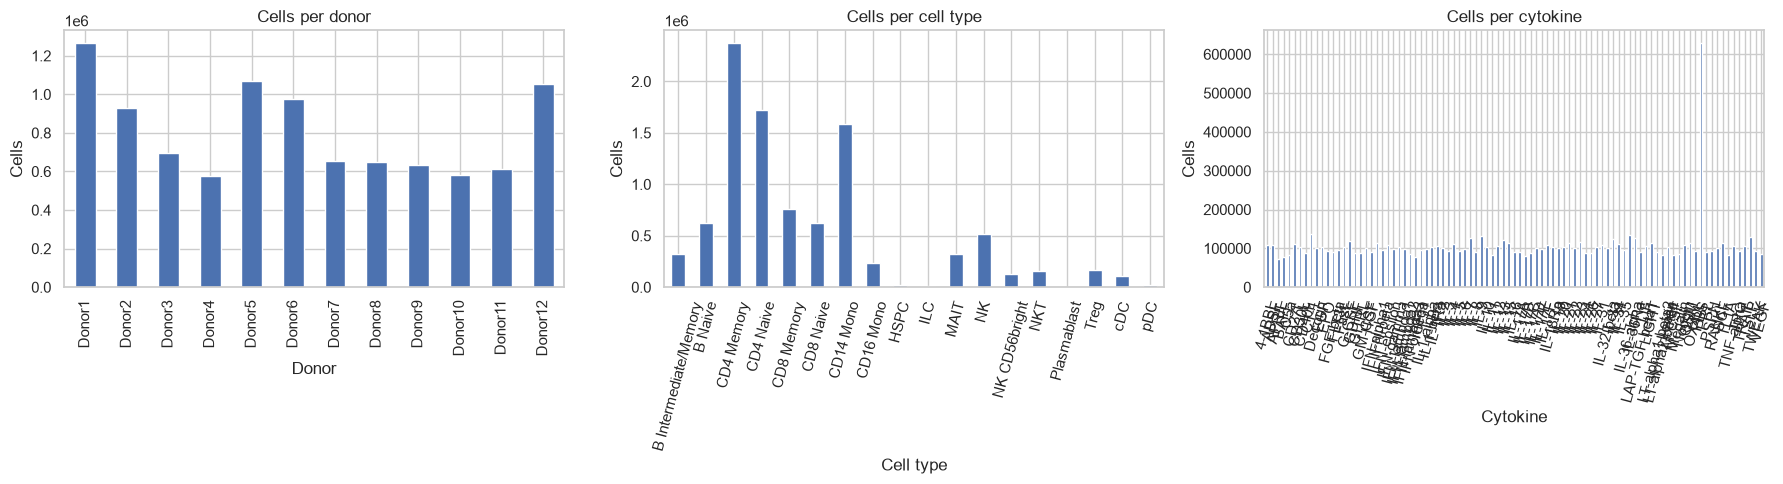

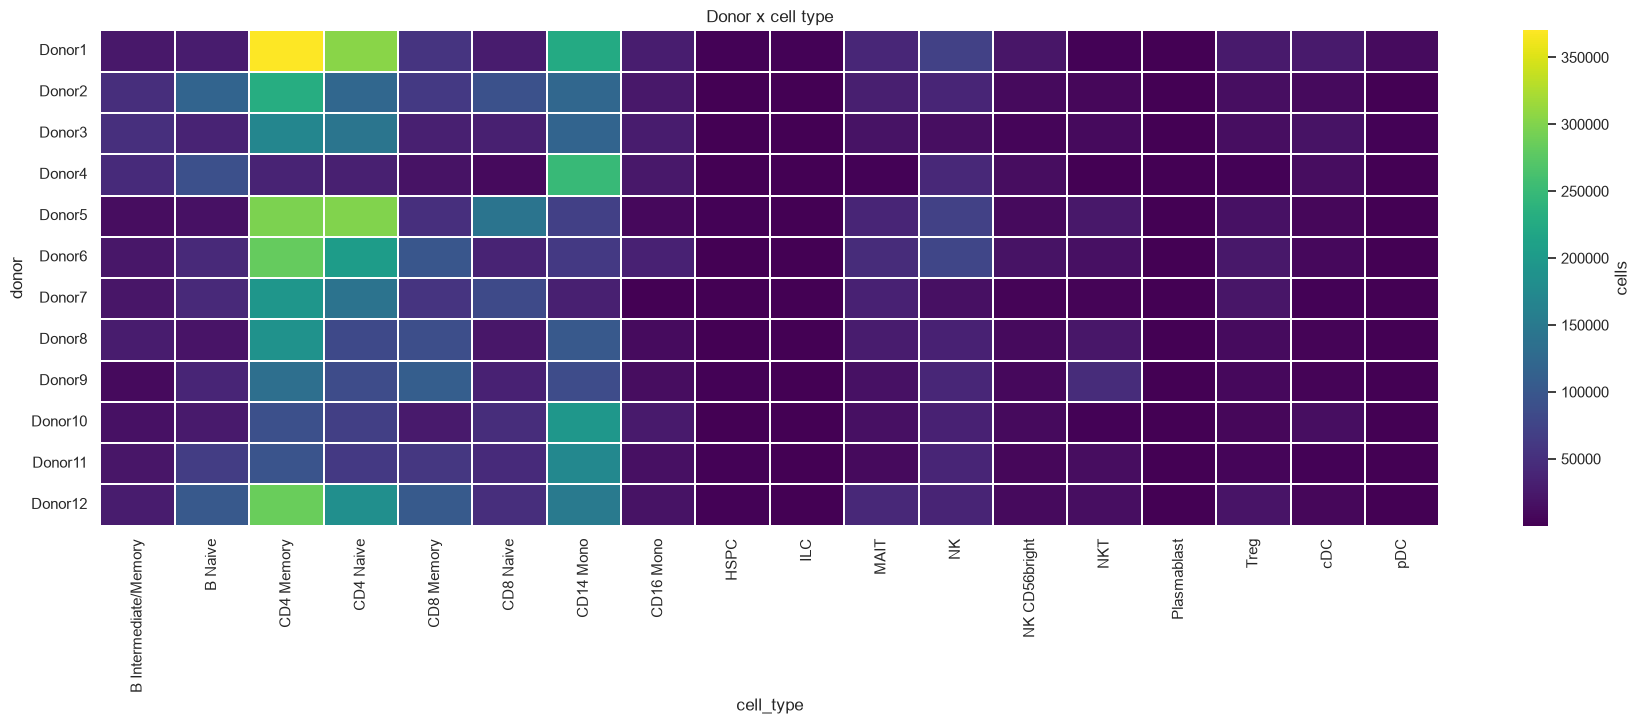

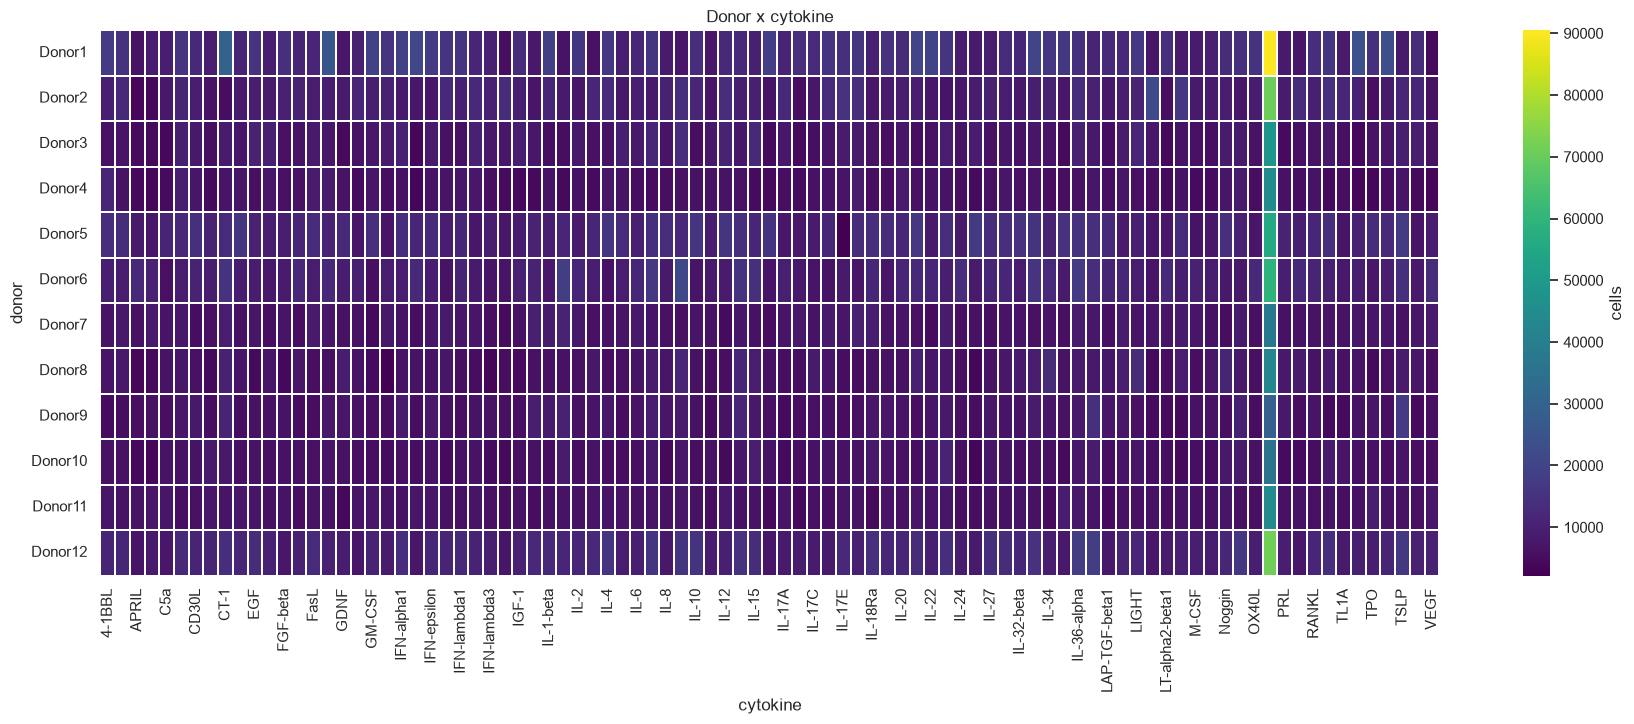

Donor x cell type x cytokine distribution


,donor,cell_type,cytokine,n_cells
0,Donor1,B Intermediate/Memory,4-1BBL,300
1,Donor1,B Intermediate/Memory,ADSF,274
2,Donor1,B Intermediate/Memory,APRIL,117
3,Donor1,B Intermediate/Memory,BAFF,197
4,Donor1,B Intermediate/Memory,C5a,200
5,Donor1,B Intermediate/Memory,CD27L,315
6,Donor1,B Intermediate/Memory,CD30L,190
7,Donor1,B Intermediate/Memory,CD40L,214
8,Donor1,B Intermediate/Memory,CT-1,599
9,Donor1,B Intermediate/Memory,Decorin,220


,n_cells
minimum,1.0
10th_percentile,6.0
25th_percentile,34.0
median,201.0
75th_percentile,542.0
90th_percentile,1351.0
maximum,26545.0


Groups with fewer than 5 cells: 1429
Groups with fewer than 10 cells: 2747
Groups with fewer than 20 cells: 4039


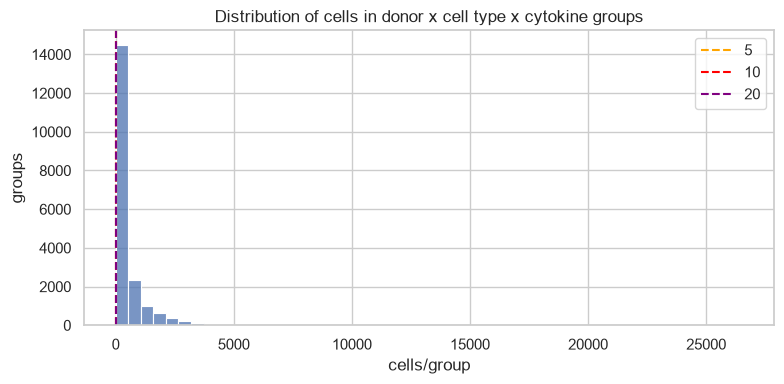

In [20]:
donor_counts = adata.obs[donor_col].value_counts().sort_index()
cell_counts = adata.obs[cell_col].value_counts().sort_index()
cytokine_counts = adata.obs[cytokine_col].value_counts().sort_index()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
donor_counts.plot(kind='bar', ax=axes[0]); axes[0].set(title='Cells per donor', xlabel='Donor', ylabel='Cells')
cell_counts.plot(kind='bar', ax=axes[1]); axes[1].set(title='Cells per cell type', xlabel='Cell type', ylabel='Cells'); axes[1].tick_params(axis='x', rotation=75)
cytokine_counts.plot(kind='bar', ax=axes[2]); axes[2].set(title='Cells per cytokine', xlabel='Cytokine', ylabel='Cells'); axes[2].tick_params(axis='x', rotation=75)
plt.tight_layout(); plt.show()

heatmaps = {}
for name, cols in [
    ('donor_x_cell_type', [donor_col, cell_col]),
    ('donor_x_cytokine', [donor_col, cytokine_col]),
    ('donor_x_cell_type_x_cytokine', [donor_col, cell_col, cytokine_col]),
]:
    if len(cols) == 2:
        pivot = adata.obs.groupby(cols).size().unstack(fill_value=0)
    else:
        temp = adata.obs.groupby(cols).size()
        pivot = temp.unstack(level=[cell_col, cytokine_col], fill_value=0)
        pivot = pivot.groupby(level=0).sum() if False else pivot
    heatmaps[name] = pivot

for title, pivot in [('Donor x cell type', heatmaps['donor_x_cell_type']),
                     ('Donor x cytokine', heatmaps['donor_x_cytokine'])]:
    fig, ax = plt.subplots(figsize=(min(18, 1.1 * pivot.shape[1] + 5), min(10, 0.45 * pivot.shape[0] + 2)))
    sns.heatmap(pivot, cmap='viridis', linewidths=.2, ax=ax, cbar_kws={'label':'cells'})
    ax.set_title(title); ax.set_xlabel(pivot.columns.name or 'category'); ax.set_ylabel(pivot.index.name or 'donor')
    plt.tight_layout(); plt.show()

triple = adata.obs.groupby([donor_col, cell_col, cytokine_col], observed=True).size()
triple_df = triple.rename('n_cells').reset_index()
print('Donor x cell type x cytokine distribution')
display(triple_df.head(20))

distribution = {
    'minimum': triple.min(), '10th_percentile': triple.quantile(.10),
    '25th_percentile': triple.quantile(.25), 'median': triple.quantile(.50),
    '75th_percentile': triple.quantile(.75), '90th_percentile': triple.quantile(.90),
    'maximum': triple.max(),
}
display(pd.DataFrame(distribution, index=['n_cells']).T)
for threshold in (5, 10, 20):
    print(f'Groups with fewer than {threshold} cells: {int((triple < threshold).sum())}')

if triple.size:
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.histplot(triple.values, bins=50, ax=ax)
    ax.set(title='Distribution of cells in donor x cell type x cytokine groups', xlabel='cells/group', ylabel='groups')
    ax.axvline(5, color='orange', linestyle='--', label='5')
    ax.axvline(10, color='red', linestyle='--', label='10')
    ax.axvline(20, color='purple', linestyle='--', label='20')
    ax.legend(); plt.tight_layout(); plt.show()

triple_df.to_csv(AUDIT_OUTPUT_DIR / 'triple_group_counts.csv', index=False)

### B4 interpretation

The quantiles and threshold counts identify how many potentially eligible profiles are lost at each minimum-cell filter. The heatmaps reveal sparse coverage and donor-specific absence patterns rather than assuming equal coverage.

### B5. NK and CD14 Mono coverage

Available cell-type labels containing NK or Mono: ['CD14 Mono', 'CD16 Mono', 'NK', 'NK CD56bright', 'NKT']

NK: 512,565 cells


cytokine,4-1BBL,ADSF,APRIL,BAFF,C5a,CD27L,CD30L,CD40L,CT-1,Decorin,...,PSPN,RANKL,SCF,TL1A,TNF-alpha,TPO,TRAIL,TSLP,TWEAK,VEGF
donor,,,,,,,,,,,,,,,,,,,,,
Donor1,984,904,378,505,504,880,751,509,1639,663,...,398,830,867,440,1455,844,1417,415,751,255
Donor2,384,518,143,150,308,412,326,292,193,365,...,516,408,569,447,388,229,372,470,464,251
Donor3,141,164,94,94,95,212,152,101,165,161,...,118,113,151,118,92,140,147,189,182,151
Donor4,931,496,251,270,337,660,502,309,430,478,...,376,481,242,437,312,248,358,473,340,279
Donor5,877,841,535,550,748,774,976,766,868,1040,...,676,754,902,505,694,830,864,1191,456,579
Donor6,718,748,985,785,458,724,881,699,1224,770,...,906,948,780,655,752,619,797,1222,700,961
Donor7,155,185,147,221,125,168,139,124,208,157,...,176,153,176,147,176,189,193,141,173,191
Donor8,328,432,190,197,304,455,324,231,541,372,...,461,366,524,285,343,249,334,447,393,232
Donor9,252,340,364,358,290,438,498,323,731,364,...,383,462,261,280,464,407,339,1082,281,408


NK, minimum 5 cells per group


,cytokine,paired_donors,pbs_eligible,treated_eligible
0,4-1BBL,12,12,12
1,ADSF,12,12,12
2,APRIL,12,12,12
3,BAFF,12,12,12
4,C5a,12,12,12
...,...,...,...,...
85,TPO,12,12,12
86,TRAIL,12,12,12
87,TSLP,12,12,12
88,TWEAK,12,12,12


NK, minimum 10 cells per group


,cytokine,paired_donors,pbs_eligible,treated_eligible
0,4-1BBL,12,12,12
1,ADSF,12,12,12
2,APRIL,12,12,12
3,BAFF,12,12,12
4,C5a,12,12,12
...,...,...,...,...
85,TPO,12,12,12
86,TRAIL,12,12,12
87,TSLP,12,12,12
88,TWEAK,12,12,12


... (6 outputs left out)

CD14 Mono, minimum 10 cells per group


,cytokine,paired_donors,pbs_eligible,treated_eligible
0,4-1BBL,12,12,12
1,ADSF,12,12,12
2,APRIL,12,12,12
3,BAFF,12,12,12
4,C5a,12,12,12
...,...,...,...,...
85,TPO,12,12,12
86,TRAIL,12,12,12
87,TSLP,12,12,12
88,TWEAK,12,12,12


CD14 Mono, minimum 20 cells per group


,cytokine,paired_donors,pbs_eligible,treated_eligible
0,4-1BBL,12,12,12
1,ADSF,12,12,12
2,APRIL,12,12,12
3,BAFF,12,12,12
4,C5a,12,12,12
...,...,...,...,...
85,TPO,12,12,12
86,TRAIL,12,12,12
87,TSLP,12,12,12
88,TWEAK,12,12,12


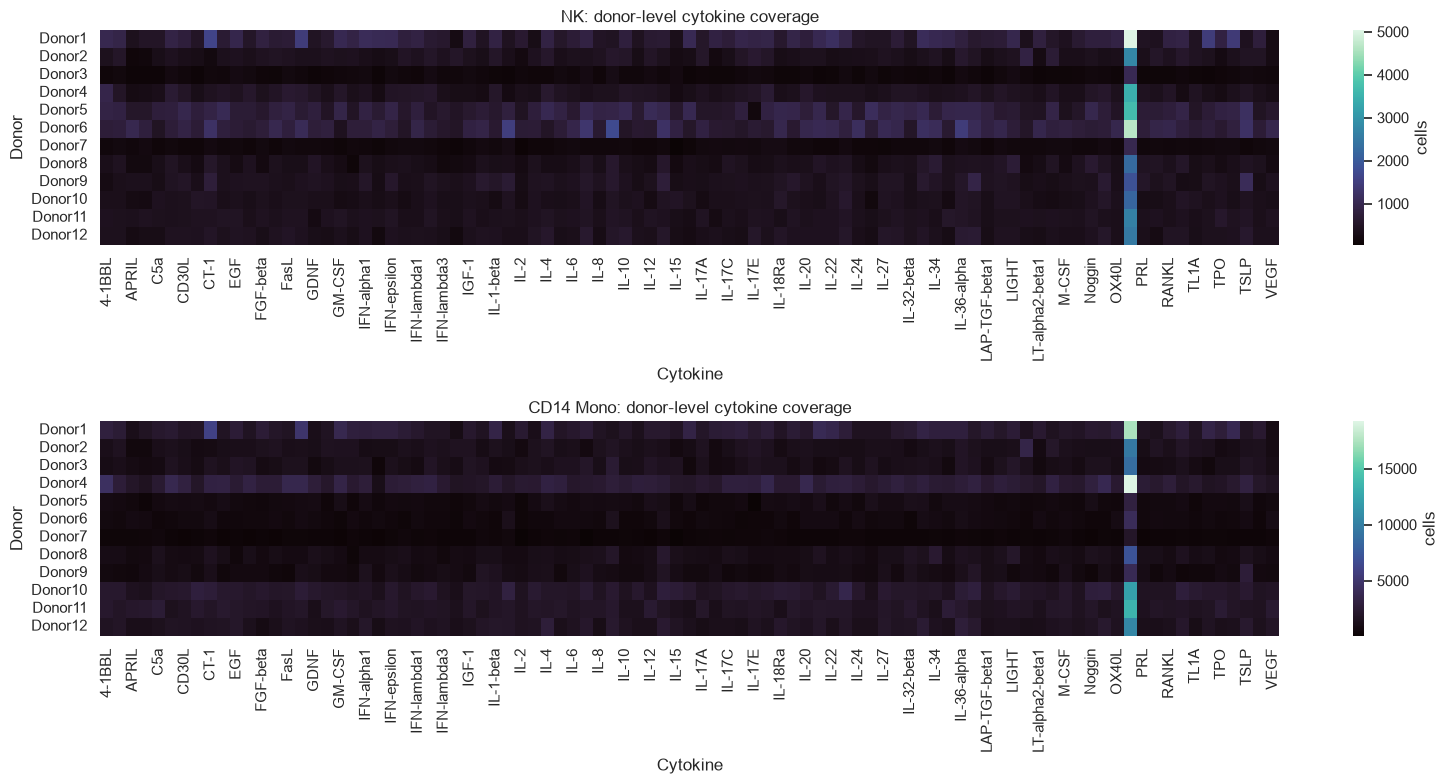

In [21]:
forct = {str(v): v for v in adata.obs[cell_col].dropna().unique()}
print('Available cell-type labels containing NK or Mono:',
      sorted({v for v in adata.obs[cell_col].dropna().unique() if 'NK' in str(v).upper() or 'MONO' in str(v).upper()}))

cell_targets = [c for c in ['NK', 'CD14 Mono', 'CD14_Mono'] if c in set(adata.obs[cell_col].astype(str))]
coverage_frames = {}
paired_counts = {}

for target in cell_targets:
    sub = adata.obs[adata.obs[cell_col].astype(str) == target]
    coverage = sub.groupby([donor_col, cytokine_col]).size().unstack(fill_value=0)
    coverage_frames[target] = coverage
    print(f'\n{target}: {len(sub):,} cells')
    display(coverage)

    pbs_values = [v for v in adata.obs[cytokine_col].dropna().unique() if str(v).upper() == 'PBS']
    if pbs_values:
        pbs = pbs_values[0]
        for threshold in (5, 10, 20):
            pbs_donors = set(coverage.index[coverage.get(pbs, pd.Series(0, index=coverage.index)) >= threshold])
            rows = []
            for cytokine in coverage.columns:
                if cytokine == pbs:
                    continue
                treated_donors = set(coverage.index[coverage[cytokine] >= threshold])
                paired = len(pbs_donors & treated_donors)
                rows.append({'cytokine': cytokine, 'paired_donors': paired,
                             'pbs_eligible': len(pbs_donors), 'treated_eligible': len(treated_donors)})
            paired_counts[(target, threshold)] = pd.DataFrame(rows)
            print(f'{target}, minimum {threshold} cells per group')
            display(paired_counts[(target, threshold)])

if coverage_frames:
    fig, axes = plt.subplots(len(coverage_frames), 1,
                             figsize=(16, max(4, 4 * len(coverage_frames))), squeeze=False)
    for ax, (target, coverage) in zip(axes[:, 0], coverage_frames.items()):
        sns.heatmap(coverage, cmap='mako', ax=ax, cbar_kws={'label':'cells'})
        ax.set_title(f'{target}: donor-level cytokine coverage')
        ax.set_xlabel('Cytokine'); ax.set_ylabel('Donor')
    plt.tight_layout(); plt.show()

pd.concat([
    df.assign(cell_type=target, minimum_cells=threshold)
    for (target, threshold), df in paired_counts.items()
], ignore_index=True).to_csv(AUDIT_OUTPUT_DIR / 'nk_mono_paired_coverage.csv', index=False) if paired_counts else None

## 4. Section C: Inspect the Parse-provided pseudobulks

### C1. File-level inspection

In [22]:
parse_h5ad_files = sorted(PSEUDOBULK_DIR.rglob('*.h5ad'))
print(f'Parse H5AD files found: {len(parse_h5ad_files)}')

representative = []
for p in parse_h5ad_files:
    row = {'filename': str(p.relative_to(PSEUDOBULK_DIR)), 'size': format_size(p.stat().st_size),
           'file_type': 'AnnData/HDF5', 'readable': False}
    try:
        a = ad.read_h5ad(p, backed='r')
        row.update({'readable': True, 'shape': str(a.shape), 'obs_columns': ', '.join(a.obs.columns),
                    'var_columns': ', '.join(a.var.columns), 'layers': ', '.join(a.layers.keys()) or '(none)',
                    'uns_keys': ', '.join(a.uns.keys()) or '(none)'})
        a.file.close()
    except Exception as exc:
        row['error'] = str(exc)
    representative.append(row)
parse_metadata_table = pd.DataFrame(representative)
display(parse_metadata_table.head(200))

parse_metadata_table.to_csv(AUDIT_OUTPUT_DIR / 'parse_file_metadata.csv', index=False)

Parse H5AD files found: 2088


,filename,size,file_type,readable,error
0,PBS_by_well/pbulk_B_cell_PBS_sum.h5ad,19.93 MB,AnnData/HDF5,False,"sequence item 0: expected str instance, NoneTy..."
1,PBS_by_well/pbulk_CD14_Mono_PBS_sum.h5ad,29.50 MB,AnnData/HDF5,False,"sequence item 0: expected str instance, NoneTy..."
2,PBS_by_well/pbulk_CD16_Mono_PBS_sum.h5ad,11.85 MB,AnnData/HDF5,False,"sequence item 0: expected str instance, NoneTy..."
3,PBS_by_well/pbulk_CD4_Memory_T_cell_PBS_sum.h5ad,27.56 MB,AnnData/HDF5,False,"sequence item 0: expected str instance, NoneTy..."
4,PBS_by_well/pbulk_CD4_Naive_T_cell_PBS_sum.h5ad,30.81 MB,AnnData/HDF5,False,"sequence item 0: expected str instance, NoneTy..."
...,...,...,...,...,...
195,pbulk_CD14_Mono_TNF-alpha.h5ad,7.04 MB,AnnData/HDF5,False,"sequence item 0: expected str instance, NoneTy..."
196,pbulk_CD14_Mono_TPO.h5ad,7.08 MB,AnnData/HDF5,False,"sequence item 0: expected str instance, NoneTy..."
197,pbulk_CD14_Mono_TRAIL.h5ad,7.30 MB,AnnData/HDF5,False,"sequence item 0: expected str instance, NoneTy..."
198,pbulk_CD14_Mono_TSLP.h5ad,7.98 MB,AnnData/HDF5,False,"sequence item 0: expected str instance, NoneTy..."


### C2. Pseudobulk aggregation level

In [23]:
def infer_psbulk_group(row, columns):
    obs_cols = list(row)
    def find(likely):
        return find_metadata_column(obs_cols, likely)
    return {
        'donor_col': find(['donor', 'donor_id']),
        'cell_col': find(['cell_type', 'celltype']),
        'cytokine_col': find(['cytokine', 'stimulus']),
        'treatment_col': find(['treatment', 'status']),
        'well_col': find(['well', 'bc1_well', 'bc2_well', 'bc3_well']),
        'sample_col': find(['sample', 'sample_id']),
    }

psbulk_summary = []
for p in parse_h5ad_files:
    try:
        a = ad.read_h5ad(p, backed='r')
        cols = list(a.obs.columns)
        mapping = infer_psbulk_group(a.obs, cols)
        def nunique(col):
            return int(a.obs[col].nunique(dropna=True)) if col else None
        def values(col):
            return ', '.join(map(str, a.obs[col].dropna().unique()[:8])) if col else None
        row = {
            'filename': str(p.relative_to(PSEUDOBULK_DIR)), 'profiles': a.n_obs,
            'unique_donors': nunique(mapping['donor_col']),
            'unique_cell_types': nunique(mapping['cell_col']),
            'unique_cytokines': nunique(mapping['cytokine_col']),
            'donor_values': values(mapping['donor_col']),
            'cell_values': values(mapping['cell_col']),
            'cytokine_values': values(mapping['cytokine_col']),
            'well_count': nunique(mapping['well_col']),
            'obs_columns': ', '.join(cols),
        }
        a.file.close()
    except Exception as exc:
        row = {'filename': str(p.relative_to(PSEUDOBULK_DIR)), 'error': str(exc)}
    psbulk_summary.append(row)

psbulk_summary_df = pd.DataFrame(psbulk_summary)
display(psbulk_summary_df.head(200))
psbulk_summary_df.to_csv(AUDIT_OUTPUT_DIR / 'parse_profile_summary.csv', index=False)

,filename,profiles,unique_donors,unique_cell_types,unique_cytokines,donor_values,cell_values,cytokine_values,well_count,obs_columns
0,PBS_by_well/pbulk_B_cell_PBS_sum.h5ad,72,12,1,1,"Donor1, Donor10, Donor11, Donor12, Donor2, Don...",B_cell,PBS,6.0,"donor, bc1_well, sample, species, bc1_wind, cy..."
1,PBS_by_well/pbulk_CD14_Mono_PBS_sum.h5ad,72,12,1,1,"Donor1, Donor10, Donor11, Donor12, Donor2, Don...",CD14_Mono,PBS,6.0,"donor, bc1_well, sample, species, bc1_wind, cy..."
2,PBS_by_well/pbulk_CD16_Mono_PBS_sum.h5ad,72,12,1,1,"Donor1, Donor10, Donor11, Donor12, Donor2, Don...",CD16_Mono,PBS,6.0,"donor, bc1_well, sample, species, bc1_wind, cy..."
3,PBS_by_well/pbulk_CD4_Memory_T_cell_PBS_sum.h5ad,72,12,1,1,"Donor1, Donor10, Donor11, Donor12, Donor2, Don...",CD4_Memory_T_cell,PBS,6.0,"donor, bc1_well, sample, species, bc1_wind, cy..."
4,PBS_by_well/pbulk_CD4_Naive_T_cell_PBS_sum.h5ad,72,12,1,1,"Donor1, Donor10, Donor11, Donor12, Donor2, Don...",CD4_Naive_T_cell,PBS,6.0,"donor, bc1_well, sample, species, bc1_wind, cy..."
...,...,...,...,...,...,...,...,...,...,...
195,pbulk_CD14_Mono_TNF-alpha.h5ad,12,12,1,1,"Donor1, Donor10, Donor11, Donor12, Donor2, Don...",CD14_Mono,TNF-alpha,1.0,"donor, cytokine, sample, species, bc1_wind, bc..."
196,pbulk_CD14_Mono_TPO.h5ad,12,12,1,1,"Donor1, Donor10, Donor11, Donor12, Donor2, Don...",CD14_Mono,TPO,1.0,"donor, cytokine, sample, species, bc1_wind, bc..."
197,pbulk_CD14_Mono_TRAIL.h5ad,12,12,1,1,"Donor1, Donor10, Donor11, Donor12, Donor2, Don...",CD14_Mono,TRAIL,1.0,"donor, cytokine, sample, species, bc1_wind, bc..."
198,pbulk_CD14_Mono_TSLP.h5ad,12,12,1,1,"Donor1, Donor10, Donor11, Donor12, Donor2, Don...",CD14_Mono,TSLP,1.0,"donor, cytokine, sample, species, bc1_wind, bc..."


### C3. Expression-value inspection

In [24]:
# Load a few representative Parse files only: one cytokine, PBS, and PBS-by-well.
def find_existing(names):
    return [p for p in names if p.exists()] 

rep_candidates = []
for pattern in ['*NK*IFN-beta*.h5ad', '*CD14_Mono*IFN-beta*.h5ad', '*NK*PBS.h5ad', '*CD14_Mono*PBS.h5ad']:
    rep_candidates += list(PSEUDOBULK_DIR.glob(pattern))
for p in PSEUDOBULK_DIR.glob('PBS_by_well/*NK*PBS*.h5ad'):
    rep_candidates.append(p)
rep_candidates = list(dict.fromkeys(rep_candidates))[:8]

psbulk_matrix_rows = []
for p in rep_candidates:
    a = ad.read_h5ad(p, backed='r')
    psbulk_matrix_rows.append({'component': 'X', 'filename': str(p.relative_to(PSEUDOBULK_DIR)),
                               **matrix_sample_stats(a.X)})
    for name in a.layers.keys():
        psbulk_matrix_rows.append({'component': f'layer:{name}',
                                   'filename': str(p.relative_to(PSEUDOBULK_DIR)),
                                   **matrix_sample_stats(a.layers[name])})
    a.file.close()
display(pd.DataFrame(psbulk_matrix_rows))

for p in rep_candidates[:4]:
    a = ad.read_h5ad(p, backed='r')
    x = a.X[:]
    if sparse.issparse(x):
        library_sizes = np.asarray(x.sum(axis=1)).ravel()
    else:
        library_sizes = np.asarray(x).sum(axis=1)
    print(p.relative_to(PSEUDOBULK_DIR), 'library-size range:',
          (float(library_sizes.min()), float(library_sizes.max()), float(np.median(library_sizes))))
    display(pd.DataFrame({'library_size': library_sizes}).describe().T)
    a.file.close()

,component,filename,dtype,sparse,min,max,mean,median,negative,nan,inf,integer_like_fraction,sample_shape
0,X,pbulk_NK_CD56hi_IFN-beta.h5ad,float32,True,0.0,905.000000,6.859167,0.000000,False,False,False,1.000000,"(12, 500)"
1,layer:None,pbulk_NK_CD56hi_IFN-beta.h5ad,float32,True,0.0,905.000000,6.859167,0.000000,False,False,False,1.000000,"(12, 500)"
2,layer:psbulk_props,pbulk_NK_CD56hi_IFN-beta.h5ad,float64,False,0.0,0.888889,0.046539,0.000000,False,False,False,0.676167,"(12, 500)"
3,X,pbulk_NK_CD56low_IFN-beta.h5ad,float32,True,0.0,3903.000000,23.799000,0.000000,False,False,False,1.000000,"(12, 500)"
4,layer:None,pbulk_NK_CD56low_IFN-beta.h5ad,float32,True,0.0,3903.000000,23.799000,0.000000,False,False,False,1.000000,"(12, 500)"
5,layer:psbulk_props,pbulk_NK_CD56low_IFN-beta.h5ad,float64,False,0.0,0.854406,0.035432,0.000000,False,False,False,0.568000,"(12, 500)"
6,X,pbulk_NKT_IFN-beta.h5ad,float32,True,0.0,896.000000,2.525000,0.000000,False,False,False,1.000000,"(12, 500)"
7,layer:None,pbulk_NKT_IFN-beta.h5ad,float32,True,0.0,896.000000,2.525000,0.000000,False,False,False,1.000000,"(12, 500)"
8,layer:psbulk_props,pbulk_NKT_IFN-beta.h5ad,float64,False,0.0,1.000000,0.037912,0.000000,False,False,False,0.810333,"(12, 500)"
9,X,pbulk_CD14_Mono_IFN-beta.h5ad,float32,True,0.0,73280.000000,186.745667,1.000000,False,False,False,1.000000,"(12, 500)"


pbulk_NK_CD56hi_IFN-beta.h5ad library-size range: (69676.0, 1663834.0, 264378.0)


,count,mean,std,min,25%,50%,75%,max
library_size,12.0,367170.09375,430968.5625,69676.0,157973.0,264378.0,337881.75,1663834.0


pbulk_NK_CD56low_IFN-beta.h5ad library-size range: (324865.0, 4419928.0, 1020672.5)


,count,mean,std,min,25%,50%,75%,max
library_size,12.0,1335638.625,1187109.125,324865.0,727380.5,1020672.5,1273083.75,4419928.0


pbulk_NKT_IFN-beta.h5ad library-size range: (3513.0, 1019492.0, 52884.5)


,count,mean,std,min,25%,50%,75%,max
library_size,12.0,138367.921875,282847.34375,3513.0,11819.5,52884.5,89605.25,1019492.0


pbulk_CD14_Mono_IFN-beta.h5ad library-size range: (1533956.0, 26749920.0, 6772489.0)


,count,mean,std,min,25%,50%,75%,max
library_size,12.0,7698559.5,6502317.0,1533956.0,3879552.25,6772489.0,8098581.75,26749920.0


### C4. Determine how the Parse pseudobulks were generated

In [25]:
# Inspect one known representative profile file and one PBS-by-well file side by side.
check_paths = [p for p in rep_candidates if p.name.endswith('_IFN-beta.h5ad')][:1]
check_paths += [p for p in rep_candidates if 'PBS_by_well' in str(p)][:1]

for p in check_paths:
    a = ad.read_h5ad(p, backed='r')
    print('\n', p.relative_to(PSEUDOBULK_DIR), a.shape)
    print('obs columns:', list(a.obs.columns))
    display(a.obs.head(10))
    print('obs key unique counts:', {c: int(a.obs[c].nunique(dropna=True)) for c in a.obs.columns})
    print('psbulk_n_cells range:' if 'psbulk_n_cells' in a.obs else 'No psbulk_n_cells column')
    if 'psbulk_n_cells' in a.obs:
        display(a.obs['psbulk_n_cells'].describe())
    a.file.close()


 pbulk_NK_CD56hi_IFN-beta.h5ad (12, 40352)
obs columns: ['donor', 'cytokine', 'sample', 'species', 'bc1_wind', 'bc1_well', 'treatment', 'psbulk_n_cells', 'psbulk_counts', 'cell_type']


,donor,cytokine,sample,species,bc1_wind,bc1_well,treatment,psbulk_n_cells,psbulk_counts,cell_type
Donor1_IFN-beta,Donor1,IFN-beta,Donor1_IFN-beta,hg38,87,H3,cytokine,284.0,1663834.0,NK_CD56hi
Donor10_IFN-beta,Donor10,IFN-beta,Donor10_IFN-beta,hg38,87,H3,cytokine,70.0,262574.0,NK_CD56hi
Donor11_IFN-beta,Donor11,IFN-beta,Donor11_IFN-beta,hg38,87,H3,cytokine,45.0,169366.0,NK_CD56hi
Donor12_IFN-beta,Donor12,IFN-beta,Donor12_IFN-beta,hg38,87,H3,cytokine,49.0,123794.0,NK_CD56hi
Donor2_IFN-beta,Donor2,IFN-beta,Donor2_IFN-beta,hg38,87,H3,cytokine,62.0,274423.0,NK_CD56hi
Donor3_IFN-beta,Donor3,IFN-beta,Donor3_IFN-beta,hg38,87,H3,cytokine,29.0,121386.0,NK_CD56hi
Donor4_IFN-beta,Donor4,IFN-beta,Donor4_IFN-beta,hg38,87,H3,cytokine,68.0,339942.0,NK_CD56hi
Donor5_IFN-beta,Donor5,IFN-beta,Donor5_IFN-beta,hg38,87,H3,cytokine,73.0,266182.0,NK_CD56hi
Donor6_IFN-beta,Donor6,IFN-beta,Donor6_IFN-beta,hg38,87,H3,cytokine,150.0,591498.0,NK_CD56hi
Donor7_IFN-beta,Donor7,IFN-beta,Donor7_IFN-beta,hg38,87,H3,cytokine,18.0,69676.0,NK_CD56hi


obs key unique counts: {'donor': 12, 'cytokine': 1, 'sample': 12, 'species': 1, 'bc1_wind': 1, 'bc1_well': 1, 'treatment': 1, 'psbulk_n_cells': 12, 'psbulk_counts': 12, 'cell_type': 1}
psbulk_n_cells range:


count     12.00000
mean      79.75000
std       72.04055
min       18.00000
25%       48.00000
50%       60.00000
75%       70.75000
max      284.00000
Name: psbulk_n_cells, dtype: float64

**C4 conclusion structure**

- **Confirmed from metadata:** only facts visible in `obs`, `var`, `uns`, filenames, and profile shapes.
- **Strongly suggested:** integer-like X values and large library-size heterogeneity can support raw-count-sum interpretation.
- **Unknown:** original generation code is required to confirm normalization target, exact aggregation code, and well handling.

## 5. Section D: Compare full data and Parse pseudobulks

In [26]:
# Compare the 40352-gene Parse gene set with the full HCD gene set.
parse_sample_path = rep_candidates[0] if rep_candidates else None
if parse_sample_path:
    parse_a = ad.read_h5ad(parse_sample_path, backed='r')
    full_genes = set(map(str, adata.var_names))
    parse_genes = set(map(str, parse_a.var_names))
    print('Full gene count:', len(full_genes))
    print('Parse representative gene count:', len(parse_genes))
    print('Intersection:', len(full_genes & parse_genes))
    print('Parse-only:', len(parse_genes - full_genes))
    print('Full-only:', len(full_genes - parse_genes))

    overlap_table = pd.DataFrame([{
        'full_genes': len(full_genes), 'parse_genes': len(parse_genes),
        'intersection': len(full_genes & parse_genes),
        'intersection_fraction_of_parse': len(full_genes & parse_genes) / len(parse_genes) if parse_genes else np.nan,
    }])
    display(overlap_table)
    parse_a.file.close()

# Exact profile matching is feasible for a Parse file whose obs has donor/cell/cytokine columns.
comparison_results = []
for p in rep_candidates:
    pa = ad.read_h5ad(p, backed='r')
    cols = list(pa.obs.columns)
    mapping = infer_psbulk_group(pa.obs, cols)
    if not all([mapping['donor_col'], mapping['cytokine_col']]):
        pa.file.close(); continue
    pa_obs = pa.obs.copy()
    pa_obs['__profile_key'] = pa_obs[mapping['donor_col']].astype(str) + '|' + pa_obs[mapping['cytokine_col']].astype(str)

    for profile_key in pa_obs['__profile_key'].drop_duplicates():
        donor, cytokine = profile_key.split('|', 1)
        mask = ((adata.obs[donor_col].astype(str) == donor) &
                (adata.obs[cytokine_col].astype(str) == cytokine))
        if not mask.any():
            continue
        if mapping['cell_col']:
            pa_cell = pa_obs.loc[pa_obs['__profile_key'] == profile_key, mapping['cell_col']].iloc[0]
            mask &= adata.obs[cell_col].astype(str) == str(pa_cell)
        if not mask.any():
            continue

        # For the requested donor/cytokine sample, aggregate a layer if counts; otherwise aggregate X.
        source = adata.layers['counts'] if 'counts' in adata.layers.keys() else adata.X
        full_indices = np.flatnonzero(mask.to_numpy())
        if len(full_indices) == 0:
            continue
        sub = source[full_indices, :]
        if sparse.issparse(sub):
            full_vec = np.asarray(sub.sum(axis=0)).ravel()
        elif hasattr(sub, 'sum'):
            sub_dense = sub[:]
            full_vec = np.asarray(sub_dense.sum(axis=0)).ravel()
        else:
            full_vec = np.asarray(sub).sum(axis=0)

        pa_index = pa_obs.index[pa_obs['__profile_key'] == profile_key][0]
        pa_pos = list(pa.obs_names).index(pa_index)
        pa_vec = np.asarray(pa.X[pa_pos:pa_pos+1, :].sum(axis=0)).ravel()

        common_genes = adata.var_names.intersection(pa.var_names)
        if len(common_genes) == 0:
            continue
        fi = adata.var_names.get_indexer(common_genes)
        pi = pa.var_names.get_indexer(common_genes)
        fv = full_vec[fi].astype(float)
        pv = pa_vec[pi].astype(float)
        comparison_results.append({
            'profile': profile_key, 'n_cells_full': len(full_indices),
            'n_common_genes': len(common_genes),
            'pearson': float(pd.Series(fv).corr(pd.Series(pv), method='pearson')),
            'spearman': float(pd.Series(fv).corr(pd.Series(pv), method='spearman')),
            'rmse': float(np.sqrt(np.mean((fv - pv) ** 2))),
        })
        if len(comparison_results) >= 10:
            break
    pa.file.close()
    if len(comparison_results) >= 10:
        break

comparison_df = pd.DataFrame(comparison_results)
print('Matched full-data/Parse profiles (up to 10)')
display(comparison_df)
comparison_df.to_csv(AUDIT_OUTPUT_DIR / 'profile_comparison.csv', index=False)

Full gene count: 40352
Parse representative gene count: 40352
Intersection: 40352
Parse-only: 0
Full-only: 0


,full_genes,parse_genes,intersection,intersection_fraction_of_parse
0,40352,40352,40352,1.0


Matched full-data/Parse profiles (up to 10)


,profile,n_cells_full,n_common_genes,pearson,spearman,rmse
0,Donor1|IFN-beta,15,40352,1.0,1.0,0.0
1,Donor10|IFN-beta,12,40352,1.0,1.0,0.0
2,Donor11|IFN-beta,14,40352,1.0,1.0,0.0
3,Donor2|IFN-beta,1,40352,1.0,1.0,0.0
4,Donor3|IFN-beta,54,40352,1.0,1.0,0.0
5,Donor4|IFN-beta,2,40352,1.0,1.0,0.0
6,Donor5|IFN-beta,42,40352,1.0,1.0,0.0
7,Donor6|IFN-beta,19,40352,1.0,1.0,0.0
8,Donor7|IFN-beta,3,40352,1.0,1.0,0.0
9,Donor8|IFN-beta,17,40352,1.0,1.0,0.0


### D interpretation

Only compare values after confirming that gene sets and expression scales are compatible. A strong match on raw-count sums would support reuse; mismatched scales or aggregation units would not. The representative matching code stops after ten profiles to keep exploration memory-safe.

## 6. Section E: Review the midterm report preprocessing requirements

In [27]:
if MIDTERM_REPORT_PATH.exists():
    print('Midterm report found:', MIDTERM_REPORT_PATH)
    try:
        import fitz
        doc = fitz.open(MIDTERM_REPORT_PATH)
        report_text = '\n'.join(page.get_text() for page in doc)
        print(report_text[:12000])
        (AUDIT_OUTPUT_DIR / 'midterm_report_extracted.txt').write_text(report_text)
    except Exception as exc:
        print('PDF present but text extraction unavailable:', exc)
        print('Install/use a PDF text extractor to inspect it, or set MIDTERM_REPORT_PATH explicitly.')
else:
    print('Midterm report not found in the repository at:', MIDTERM_REPORT_PATH)
    print('Set MIDTERM_REPORT_PATH to the uploaded PDF and rerun this section.')

Midterm report not found in the repository at: /Users/svneni/f26/idl/cyto-project/cytoX/Group51_Midterm_Report (1).pdf
Set MIDTERM_REPORT_PATH to the uploaded PDF and rerun this section.


### Preprocessing requirements to fill from the report

| Component | Full HCD dataset | Parse files | New pseudobulks |
|---|---|---|---|
| Gene filtering/HVGs | **Inspect `var['highly_variable']` and report metadata** | **Inspect overlap and metadata** | Determine from report |
| Gene count | **Inspect report and object shape** | 40352 in representative Parse file | Determine from report |
| Normalization | **Inspect X/layer/`uns['log1p']`** | **File values and metadata determine** | Apply only if report requires |
| Log transform | **Inspect `uns['log1p']`** | **Inspect source metadata** | Apply only if report requires |
| Control representation | `treatment == 'control'` / cytokine PBS likely | Parse PBS and stimulated split or PBS by well | Preserve PBS separately |
| scGen labels | Confirmed by metadata | Inspect obs | Future work; not generated here |

Until the PDF is available, no report-specific preprocessing choice should be treated as confirmed.

## 7. Section F: Summary and recommendations

Use the evidence above to complete this table. It is intentionally left as observations to avoid guessing when metadata or the report is missing.

| Component | Finding | Confidence | Recommended action |
|---|---|---|---|
| Full dataset | | | |
| Parse pseudobulks | | | |
| Aggregation level | | | |
| Donor metadata | | | |
| Gene set | | | |
| Normalization | | | |
| NK coverage | | | |
| CD14 Mono coverage | | | |
| Reusability | | | |

### Final recommendation checklist

1. Confirm the exact full HCD file (`FULL_DATA_PATH`) and exclude the subset unless it is deliberately requested.
2. Confirm whether `X` or `counts` is the raw-count matrix.
3. Verify Parse profile rows use one row per donor × cell type × cytokine.
4. Confirm raw counts versus normalized/log-normalized values with metadata and expression distributions.
5. Compare matched profiles only after gene-set and scale compatibility checks.
6. Check NK and CD14 Mono coverage at thresholds 5, 10, and 20.
7. Extract the midterm report preprocessing requirements before choosing a preprocessing pipeline.
8. If the Parse files are donor-level, raw-count sums, and cover the required combinations, consider reuse after report-aligned filtering/transformation. Otherwise generate new pseudobulks from `counts` or raw `X` from the full dataset; do not create them in this notebook.

### Save final audit state

In [28]:
summary = {
    'project_dir': str(PROJECT_DIR),
    'full_data_path': str(FULL_DATA_PATH),
    'full_shape': list(adata.shape),
    'full_obs_columns': list(adata.obs.columns),
    'full_var_columns': list(adata.var.columns),
    'full_layers': list(adata.layers.keys()),
    'full_uns_keys': list(adata.uns.keys()),
    'parse_h5ad_file_count': len(parse_h5ad_files),
}
(AUDIT_OUTPUT_DIR / 'hcd_audit_summary.json').write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

# Close the backed file after all analyses.
adata.file.close()
print('Notebook audit complete. No source data were modified and no pseudobulks/splits were generated.')

{
  "project_dir": "/Users/svneni/f26/idl/cyto-project/cytoX",
  "full_data_path": "/Users/svneni/f26/idl/cyto-project/cytoX/data/10M_PBMC_12donor_90cytokines/10M_PBMC_cytokines.h5ad",
  "full_shape": [
    9697974,
    40352
  ],
  "full_obs_columns": [
    "sample",
    "species",
    "gene_count",
    "tscp_count",
    "mread_count",
    "bc1_wind",
    "bc2_wind",
    "bc3_wind",
    "bc1_well",
    "bc2_well",
    "bc3_well",
    "log1p_n_genes_by_counts",
    "log1p_total_counts",
    "total_counts_MT",
    "pct_counts_MT",
    "log1p_total_counts_MT",
    "donor",
    "cytokine",
    "treatment",
    "cell_type"
  ],
  "full_var_columns": [
    "n_cells"
  ],
  "full_layers": [
    null
  ],
  "full_uns_keys": [],
  "parse_h5ad_file_count": 2088
}
Notebook audit complete. No source data were modified and no pseudobulks/splits were generated.
